# Calgary Building Inspections — Chapters 5–8 Analysis
**Research question:** Do building inspection failure rates differ across Calgary's geographic zones (NE, NW, SE, SW)?

This notebook contains the completer analysis supporting our work from Chapters 5–8:
- **Chapter 5:** Data Understanding (descriptive statistics, type-mix structure, temporal patterns)
- **Chapter 6:** Data Visualization
- **Chapter 7:** Model Building (Chi-Square, Logistic Regression, Decision Tree, Random Forest)
- **Chapter 8:** Model Evaluation (fair comparison with consistent imbalance handling)

Dataset: `Calgary_Inspection_Clean.csv` — structured re-extraction of the City of Calgary building inspection records from SQL.

In [1]:
%pip install --quiet pandas numpy matplotlib seaborn scipy scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve, auc,
                             confusion_matrix, ConfusionMatrixDisplay)
import warnings, os
warnings.filterwarnings('ignore')
os.makedirs('figures', exist_ok=True)
sns.set_theme(style='whitegrid', font_scale=1.05)
RANDOM_STATE = 42
pd.set_option('display.float_format', lambda x: f'{x:,.4f}' if abs(x) < 1 else f'{x:,.2f}')


[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## Chapter 5 — Data Understanding
### 5.1 Data Summary

In [2]:
df = pd.read_csv('Calgary_Inspection_Clean.csv')

# Step 1: Check for NULL values in the failed column
print('NULL in failed column:', df['failed'].isnull().sum())
print()
print('Outcomes causing NULL in failed:')
print(df[df['failed'].isnull()]['outcome_desc'].value_counts())

# Remove rows where failed is NULL
df = df[df['failed'].notnull()]
print('Rows after Step 1:', len(df))  

# Step 2: Check for Other zone records 
print('Other zone rows:', (df['zone'] == 'Other').sum())


# Step 3: Convert failed column to integer 
# Column loaded as float64 (1.0, 0.0) — convert to int (1, 0)
df['failed'] = df['failed'].astype(int)
print('failed dtype after Step 3:', df['failed'].dtype)  # int64

# Step 4: Convert date column to datetime 
df['inspection_completed_date'] = pd.to_datetime(
    df['inspection_completed_date'], errors='coerce')
print('NULL dates after conversion:',
      df['inspection_completed_date'].isnull().sum())  # 6

# Step 5: Confirm final dataset 
print()
print('=== FINAL DATASET SUMMARY ===')
print('Total rows:        ', len(df))
print('Zones present:     ', sorted(df['zone'].unique()))
print('Failed values:     ', df['failed'].unique())
print('Pass count:        ', (df['failed'] == 0).sum())
print('Non-pass count:    ', (df['failed'] == 1).sum())
print('Overall fail rate: ',
      round(df['failed'].mean() * 100, 2), '%')

NULL in failed column: 247

Outcomes causing NULL in failed:
outcome_desc
Office Procedure                       124
No Inspection                           69
Cancelled By Contractor                 46
Continue Monitoring                      4
Covered - Unable to Inspect              2
Charge Re-Inspection                     1
Blanket Permit Occupancy Acceptable      1
Name: count, dtype: int64
Rows after Step 1: 105468
Other zone rows: 0
failed dtype after Step 3: int64
NULL dates after conversion: 6

=== FINAL DATASET SUMMARY ===
Total rows:         105468
Zones present:      ['NE', 'NW', 'SE', 'SW']
Failed values:      [1 0]
Pass count:         66590
Non-pass count:     38878
Overall fail rate:  36.86 %


In [3]:
# Confirm the shape of the dataset
print('Rows:', df.shape[0])
print('Columns:', df.shape[1])
print()

# Preview the first five rows
print(df.head())
print()

# Check column data types
print(df.dtypes)
print()


# Confirm zone distribution
print('Inspections per zone:')
print(df['zone'].value_counts())
print()

# Confirm outcome distribution
print('Pass vs Non-Pass:')
print(df['failed'].value_counts())


print(f"Raw records: {len(df):,}")

# 6 records have NULL completion dates (and therefore NULL year); drop for a single consistent modeling N
df = df.dropna(subset=['inspection_year', 'failed']).copy()
df['inspection_year'] = df['inspection_year'].astype(int)
df['failed'] = df['failed'].astype(int)
N = len(df)
print(f"Final analytical dataset (non-null year): {N:,}")
print(f"Overall failure rate: {df['failed'].mean():.4f} ({df['failed'].mean()*100:.2f}%)")
df[['zone','inspection_type_desc','inspection_year','failed']].describe(include='all').T

Rows: 105468
Columns: 10

   inspection_id inspection_completed_date  inspection_year zone  latitude  \
0          91588                       NaT              NaN   SW     50.99   
1          44518                       NaT              NaN   NW     51.19   
2          37326                       NaT              NaN   SE     50.88   
3          38937                       NaT              NaN   NE     51.09   
4          36115                       NaT              NaN   SE     50.86   

   longitude            address_line inspection_type_desc  \
0    -114.08        77 KENTISH DR SW              Framing   
1    -114.08         404 LUCAS BV NW                Final   
2    -113.91       82 LAVENDER MR SE                Final   
3    -113.95      7106B TEMPLE DR NE              Framing   
4    -114.01  685 LEGACY WOODS CI SE                Final   

                 outcome_desc  failed  
0              Not Acceptable       1  
1  Acceptable with Conditions       0  
2                 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
zone,105462,4,SE,33411,NaN,NaN,NaN,NaN,NaN,NaN,NaN
inspection_type_desc,105462,14,Framing,49675,NaN,NaN,NaN,NaN,NaN,NaN,NaN
inspection_year,"105,462.00",NaN,NaN,NaN,"2,013.11",5.28,"2,000.00","2,008.00","2,013.00","2,017.00","2,026.00"
failed,"105,462.00",NaN,NaN,NaN,0.3686,0.4824,0.0000,0.0000,0.0000,1.00,1.00


### 5.2 Geographic Distribution — failure rate by zone

In [4]:

zone_summary = df.groupby('zone').agg(
    inspections=('failed','count'),
    failures=('failed','sum'),
    passes=('failed', lambda x: (x == 0).sum()),
    failure_rate=('failed','mean')
).sort_values('failure_rate', ascending=False)
zone_summary['failure_pct'] = (zone_summary['failure_rate']*100).round(2)
overall_rate = df['failed'].mean()*100
print(f"Overall average: {overall_rate:.2f}%")
print(f"Max-min zone gap: {zone_summary['failure_pct'].max() - zone_summary['failure_pct'].min():.2f} percentage points")
zone_summary

Overall average: 36.86%
Max-min zone gap: 1.81 percentage points


,inspections,failures,passes,failure_rate,failure_pct
zone,,,,,
NW,25754,9817,15937,0.3812,38.12
SE,33411,12234,21177,0.3662,36.62
SW,28880,10500,18380,0.3636,36.36
NE,17417,6324,11093,0.3631,36.31


### 5.3 Failure Rate by Inspection Type

In [5]:
type_summary = df.groupby('inspection_type_desc').agg(
    inspections=('failed','count'),
    failure_rate=('failed','mean')
).sort_values('failure_rate', ascending=False)
type_summary['failure_pct'] = (type_summary['failure_rate']*100).round(2)
type_summary['share_pct'] = (type_summary['inspections']/N*100).round(2)
print(f"Range across types: {type_summary['failure_pct'].max() - type_summary['failure_pct'].min():.1f} percentage points")
type_summary

Range across types: 72.9 percentage points


,inspections,failure_rate,failure_pct,share_pct
inspection_type_desc,,,,
Gas Final,1841,0.8240,82.40,1.75
Gas Rough,3895,0.8159,81.59,3.69
FP Rough,1426,0.7574,75.74,1.35
FP Final,19,0.4737,47.37,0.0200
Temp Gas,45,0.4667,46.67,0.0400
Final,21485,0.4560,45.60,20.37
Framing,49675,0.3807,38.07,47.10
Occupancy,3862,0.3462,34.62,3.66
Pub Protect Safety,3,0.3333,33.33,0.0000


### 5.4 Inspection Type Mix by Zone (compositional structure)
This cross-tabulation quantifies how each zone's *composition* of inspection types differs — the mechanism by which raw zone failure rates can diverge even if geography itself has no effect.

In [6]:
mix = pd.crosstab(df['zone'], df['inspection_type_desc'], normalize='index') * 100
top_types = type_summary.head(6).index.tolist()
mix_display = mix[[c for c in ['Framing','Final','Foundation','Progress','Gas Rough','Gas Final'] if c in mix.columns]].round(2)
mix_display.transpose()

zone,NE,NW,SE,SW
inspection_type_desc,,,,
Framing,48.07,52.22,44.72,44.70
Final,19.75,20.73,22.54,17.92
Foundation,9.93,10.00,10.59,9.82
Progress,9.53,4.90,9.54,12.04
Gas Rough,3.39,3.65,3.27,4.41
Gas Final,1.76,1.97,1.43,1.91


### 5.5 Mix-Adjusted Expected Failure Rates
For each zone we compute the failure rate it *would* have if its own type-mix were applied to the city-wide per-type failure rates. The gap between actual and expected isolates the "pure zone" residual after composition is accounted for.

In [7]:
type_fail = df.groupby('inspection_type_desc')['failed'].mean()
rows = []
for z in ['NE','NW','SE','SW']:
    zdf = df[df['zone']==z]
    zone_share = zdf['inspection_type_desc'].value_counts(normalize=True)
    expected = (type_fail * zone_share).fillna(0).sum()
    actual = zdf['failed'].mean()
    rows.append({'zone': z, 'actual_pct': actual*100, 'expected_given_mix_pct': expected*100,
                 'pure_zone_residual_pp': (actual-expected)*100})
mix_adj = pd.DataFrame(rows).set_index('zone').round(2)
raw_gap = mix_adj.loc['NW','actual_pct'] - mix_adj.loc['NE','actual_pct']
mix_gap = mix_adj.loc['NW','expected_given_mix_pct'] - mix_adj.loc['NE','expected_given_mix_pct']
print(f"NW vs NE raw gap: {raw_gap:.2f}pp | explained by type-mix: {mix_gap:.2f}pp | pure zone residual: {raw_gap-mix_gap:.2f}pp")
mix_adj

NW vs NE raw gap: 1.81pp | explained by type-mix: 1.68pp | pure zone residual: 0.13pp


,actual_pct,expected_given_mix_pct,pure_zone_residual_pp
zone,,,
NE,36.31,36.48,-0.1700
NW,38.12,38.16,-0.0400
SE,36.62,36.32,0.2900
SW,36.36,36.56,-0.2000


### 5.6 Temporal Structure — year-level summary

In [8]:
yearly = df.groupby('inspection_year').agg(
    inspections=('failed','count'),
    failures=('failed','sum'),
    failure_rate=('failed','mean')
)
yearly['failure_pct'] = (yearly['failure_rate']*100).round(2)
yearly_main = yearly[yearly['inspections'] >= 1000]
print(f"Years with n>=1,000: {len(yearly_main)}")
print(f"Failure-rate spread across those years: {yearly_main['failure_pct'].min():.1f}% to {yearly_main['failure_pct'].max():.1f}% "
      f"({yearly_main['failure_pct'].max()-yearly_main['failure_pct'].min():.1f}pp)")
boom = df[df['inspection_year'].isin([2006,2007])]['failed'].mean()*100
recent = df[df['inspection_year']>=2020]['failed'].mean()*100
print(f"Boom period 2006-07: {boom:.1f}% | Recent period 2020-23: {recent:.1f}%")
yearly_main[['inspections','failures','failure_pct']]

Years with n>=1,000: 19
Failure-rate spread across those years: 22.7% to 48.6% (25.9pp)
Boom period 2006-07: 47.2% | Recent period 2020-23: 28.9%


,inspections,failures,failure_pct
inspection_year,,,
2005,6402,1672,26.12
2006,8442,3846,45.56
2007,10038,4879,48.61
2008,2624,873,33.27
2009,3026,686,22.67
2010,3299,928,28.13
2011,4418,1585,35.88
2012,7693,3285,42.70
2013,8321,3472,41.73


**Chapter 5 key findings**
1. The overall failure rate is ~36.9% — roughly one in three inspections does not pass.
2. Zone failure rates span only ~1.8pp (NW 38.1% vs NE 36.3%), while inspection types span ~73pp (Gas Final ~82% vs Site Safety ~10%).
3. The type-mix cross-tab shows NW carries the highest Framing share (52.2% vs ~44.7% in SE/SW) — composition, not geography, drives most of its elevated raw rate.
4. Mix-adjusted analysis: of the 1.81pp NW–NE gap, ~1.7pp is explained by type composition; the pure-zone residual is ~0.1pp.
5. Failure rates carry strong temporal structure (23%–49% across years), peaking in the 2006–07 construction boom and declining to ~29% in 2020–23 — making `inspection_year` a legitimate predictor.

## Chapter 6 — Data Visualization

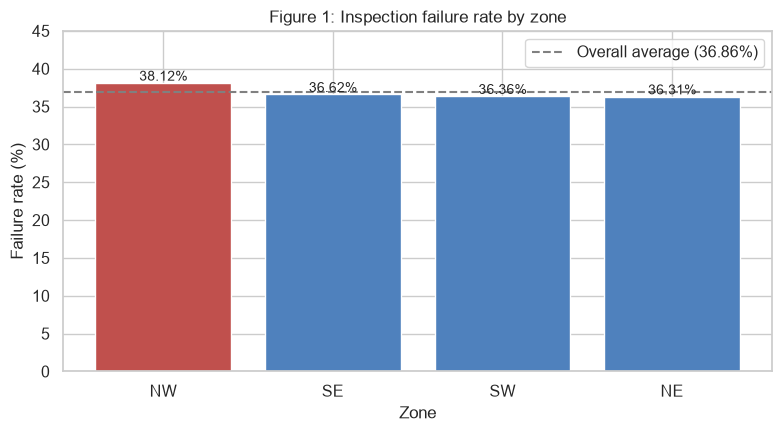

In [9]:
# Figure 1: Failure rate by zone
fig, ax = plt.subplots(figsize=(8,4.5))
zs = zone_summary.sort_values('failure_pct', ascending=False)
bars = ax.bar(zs.index, zs['failure_pct'], color=['#c0504d' if z=='NW' else '#4f81bd' for z in zs.index])
ax.axhline(overall_rate, ls='--', color='gray', label=f'Overall average ({overall_rate:.2f}%)')
for b, v in zip(bars, zs['failure_pct']):
    ax.text(b.get_x()+b.get_width()/2, v+0.3, f'{v:.2f}%', ha='center', fontsize=10)
ax.set_ylabel('Failure rate (%)'); ax.set_xlabel('Zone'); ax.set_ylim(0, 45)
ax.set_title('Figure 1: Inspection failure rate by zone'); ax.legend()
plt.tight_layout(); plt.savefig('figures/fig1_zone_failure.png', dpi=150); plt.show()

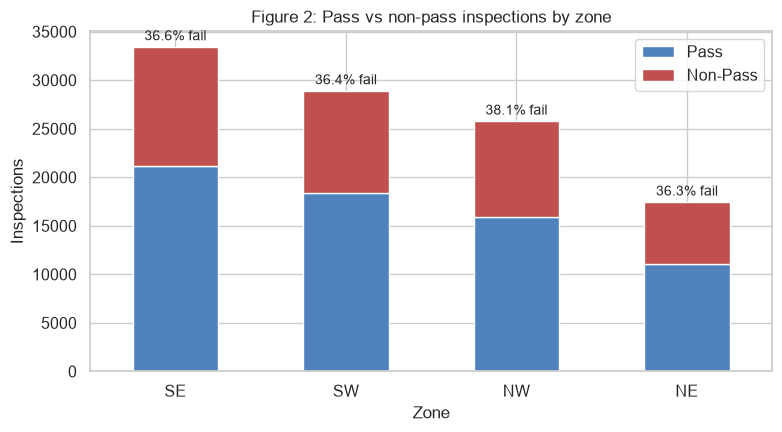

In [10]:
# Figure 2: Pass vs non-pass counts by zone (stacked)
fig, ax = plt.subplots(figsize=(8,4.5))
counts = df.groupby(['zone','failed']).size().unstack()
counts.columns = ['Pass','Non-Pass']
counts = counts.loc[['SE','SW','NW','NE']]
counts.plot(kind='bar', stacked=True, ax=ax, color=['#4f81bd','#c0504d'], rot=0)
for i, z in enumerate(counts.index):
    total = counts.loc[z].sum()
    fail_pct = counts.loc[z,'Non-Pass']/total*100
    ax.text(i, total+700, f'{fail_pct:.1f}% fail', ha='center', fontsize=10)
ax.set_ylabel('Inspections'); ax.set_xlabel('Zone')
ax.set_title('Figure 2: Pass vs non-pass inspections by zone')
plt.tight_layout(); plt.savefig('figures/fig2_stacked_zone.png', dpi=150); plt.show()

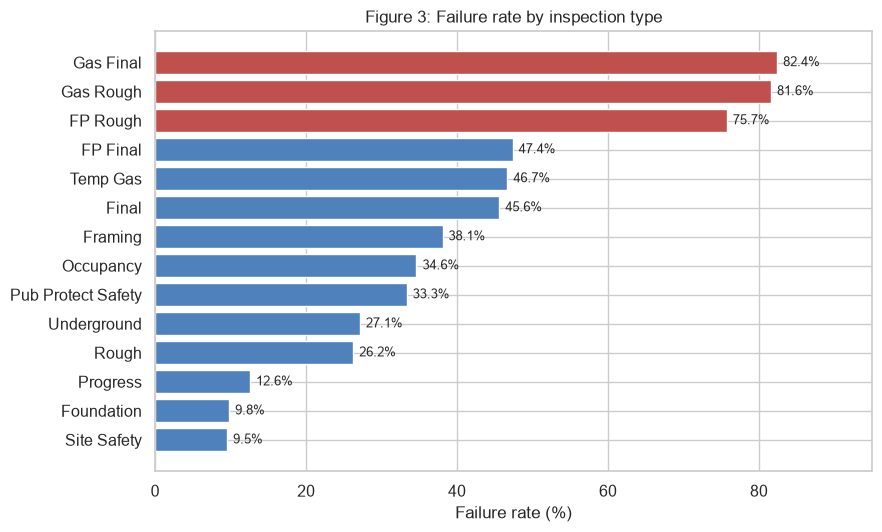

In [11]:
# Figure 3: Failure rate by inspection type
fig, ax = plt.subplots(figsize=(9,5.5))
ts = type_summary.sort_values('failure_pct')
colors = ['#c0504d' if v > 50 else '#4f81bd' for v in ts['failure_pct']]
ax.barh(ts.index, ts['failure_pct'], color=colors)
for i, v in enumerate(ts['failure_pct']):
    ax.text(v+0.8, i, f'{v:.1f}%', va='center', fontsize=9)
ax.set_xlabel('Failure rate (%)'); ax.set_xlim(0, 95)
ax.set_title('Figure 3: Failure rate by inspection type')
plt.tight_layout(); plt.savefig('figures/fig3_type_failure.png', dpi=150); plt.show()

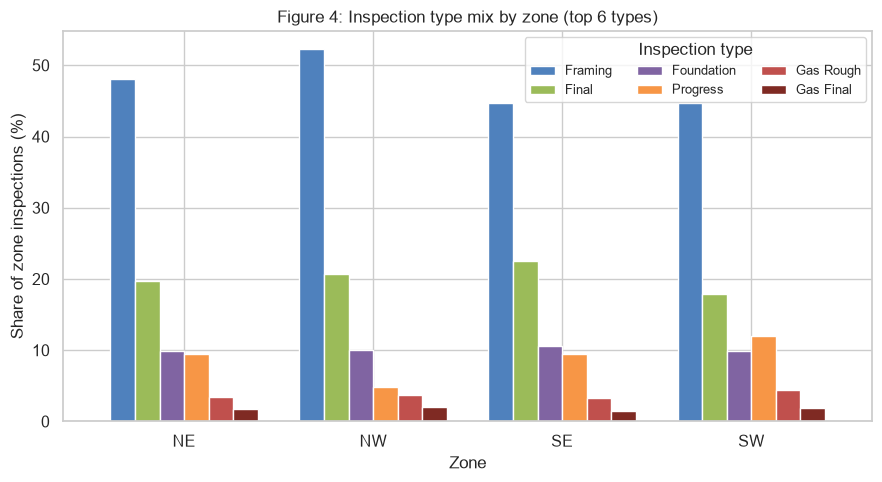

In [12]:
# Figure 4: Inspection type mix by zone (the compositional evidence)
fig, ax = plt.subplots(figsize=(9,5))
mix_plot = mix[['Framing','Final','Foundation','Progress','Gas Rough','Gas Final']]
mix_plot.plot(kind='bar', ax=ax, rot=0, width=0.78,
              color=['#4f81bd','#9bbb59','#8064a2','#f79646','#c0504d','#7f2a23'])
ax.set_ylabel('Share of zone inspections (%)'); ax.set_xlabel('Zone')
ax.set_title('Figure 4: Inspection type mix by zone (top 6 types)')
ax.legend(title='Inspection type', fontsize=9, ncol=3)
plt.tight_layout(); plt.savefig('figures/fig4_type_mix.png', dpi=150); plt.show()

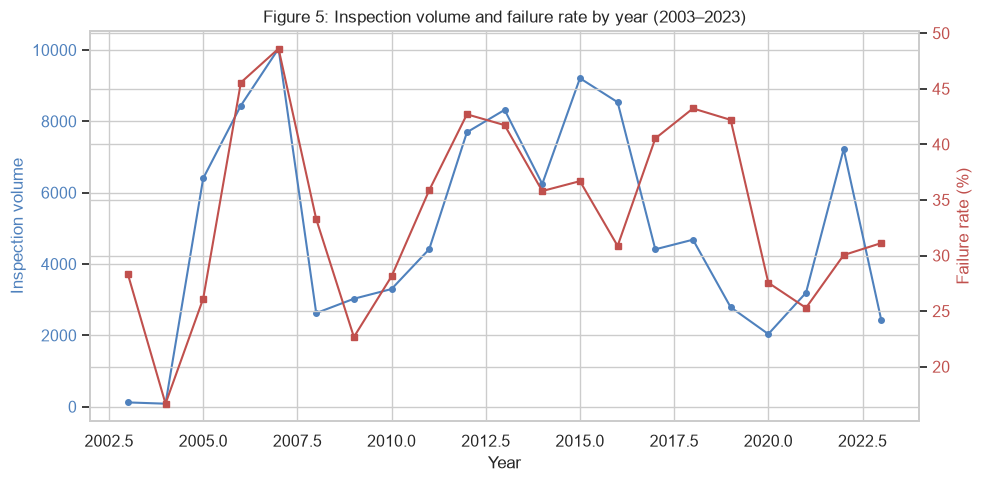

In [13]:
# Figure 5: Temporal trends — volume vs failure rate (dual axis)
fig, ax1 = plt.subplots(figsize=(10,5))
y = yearly[(yearly.index >= 2003) & (yearly.index <= 2023)]
ax1.plot(y.index, y['inspections'], color='#4f81bd', marker='o', ms=4, label='Inspections')
ax1.set_ylabel('Inspection volume', color='#4f81bd'); ax1.set_xlabel('Year')
ax1.tick_params(axis='y', labelcolor='#4f81bd')
ax2 = ax1.twinx()
ax2.plot(y.index, y['failure_pct'], color='#c0504d', marker='s', ms=4, label='Failure rate')
ax2.set_ylabel('Failure rate (%)', color='#c0504d')
ax2.tick_params(axis='y', labelcolor='#c0504d')
ax1.set_title('Figure 5: Inspection volume and failure rate by year (2003–2023)')
plt.tight_layout(); plt.savefig('figures/fig5_temporal.png', dpi=150); plt.show()

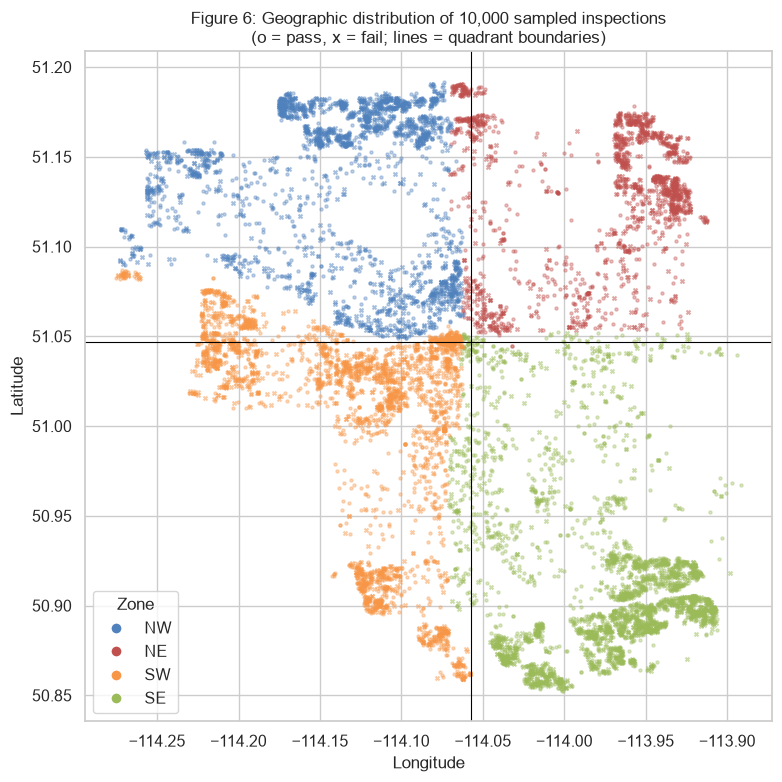

In [14]:
# Figure 6: Geographic scatter of sampled inspections
sample = df.sample(10000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(8,8))
zone_colors = {'NW':'#4f81bd','NE':'#c0504d','SW':'#f79646','SE':'#9bbb59'}
for z, g in sample.groupby('zone'):
    passed = g[g['failed']==0]; failed_g = g[g['failed']==1]
    ax.scatter(passed['longitude'], passed['latitude'], s=5, alpha=0.35, color=zone_colors[z], marker='o')
    ax.scatter(failed_g['longitude'], failed_g['latitude'], s=8, alpha=0.5, color=zone_colors[z], marker='x')
ax.axhline(51.047, color='black', lw=0.8); ax.axvline(-114.057, color='black', lw=0.8)
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
ax.set_title('Figure 6: Geographic distribution of 10,000 sampled inspections\n(o = pass, x = fail; lines = quadrant boundaries)')
handles = [plt.Line2D([0],[0], marker='o', color='w', markerfacecolor=c, ms=8, label=z) for z,c in zone_colors.items()]
ax.legend(handles=handles, title='Zone')
plt.tight_layout(); plt.savefig('figures/fig6_geo.png', dpi=150); plt.show()

## Chapter 7 — Model Building
### 7.1 Data Preparation
- Predictors: `zone`, `inspection_type_desc`, and `inspection_year` (added on the strength of the ~26pp temporal spread shown in 5.6).
- Target: `failed` (1 = non-pass, 0 = pass). Class split is 63:37 — a moderate imbalance.
- **Imbalance handling is applied consistently to every model** (`class_weight='balanced'`) so the comparison is fair. Without this, any model evaluated at the default 0.5 threshold under-detects failures, which is a threshold artifact rather than a property of the algorithm.
- One-hot encoding for the two categorical predictors; 70/30 stratified train/test split.

In [15]:
features = ['zone', 'inspection_type_desc', 'inspection_year']
X = pd.get_dummies(df[features], columns=['zone','inspection_type_desc'], drop_first=True)
y = df['failed']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} | Test: {len(X_test):,} | Features: {X.shape[1]}")
print(f"Train failure rate: {y_train.mean():.4f} | Test failure rate: {y_test.mean():.4f}")
list(X.columns)

Train: 73,823 | Test: 31,639 | Features: 17
Train failure rate: 0.3686 | Test failure rate: 0.3686


['inspection_year',
 'zone_NW',
 'zone_SE',
 'zone_SW',
 'inspection_type_desc_FP Rough',
 'inspection_type_desc_Final',
 'inspection_type_desc_Foundation',
 'inspection_type_desc_Framing',
 'inspection_type_desc_Gas Final',
 'inspection_type_desc_Gas Rough',
 'inspection_type_desc_Occupancy',
 'inspection_type_desc_Progress',
 'inspection_type_desc_Pub Protect Safety',
 'inspection_type_desc_Rough',
 'inspection_type_desc_Site Safety',
 'inspection_type_desc_Temp Gas',
 'inspection_type_desc_Underground']

## 7.2 and 8.2 Chi-Square Test of Independence (zone vs outcome)

In [16]:
contingency = pd.crosstab(df['zone'], df['failed'])
contingency.columns = ['Pass','Non-Pass']
chi2, p_value, dof, expected = stats.chi2_contingency(contingency)
n_total = contingency.values.sum()
cramers_v = np.sqrt(chi2 / (n_total * (min(contingency.shape)-1)))
print(f"Chi-square statistic: {chi2:.2f}")
print(f"p-value: {p_value:.3e}")
print(f"Degrees of freedom: {dof}")
print(f"Cramer's V: {cramers_v:.4f} (negligible effect size)")
print(f"Decision at alpha=0.05: {'REJECT H0' if p_value < 0.05 else 'FAIL TO REJECT H0'}")
contingency

Chi-square statistic: 23.78
p-value: 2.782e-05
Degrees of freedom: 3
Cramer's V: 0.0150 (negligible effect size)
Decision at alpha=0.05: REJECT H0


,Pass,Non-Pass
zone,,
NE,11093,6324
NW,15937,9817
SE,21177,12234
SW,18380,10500


### 7.3 Logistic Regression
The standard interpretable model for a binary outcome with categorical predictors. Each coefficient converts to an odds ratio measuring how a predictor shifts the odds of failure relative to its reference category, holding the other predictors constant — exactly the "zone effect after controlling for inspection type" quantity the research question requires.

In [17]:
logreg = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
logreg.fit(X_train, y_train)
coefs = pd.DataFrame({'feature': X.columns, 'coefficient': logreg.coef_[0]})
coefs['odds_ratio'] = np.exp(coefs['coefficient'])
coefs.sort_values('odds_ratio', ascending=False).head(10)


,feature,coefficient,odds_ratio
8,inspection_type_desc_Gas Final,1.92,6.83
9,inspection_type_desc_Gas Rough,1.80,6.03
4,inspection_type_desc_FP Rough,1.50,4.50
5,inspection_type_desc_Final,0.1824,1.20
2,zone_SE,0.0210,1.02
15,inspection_type_desc_Temp Gas,0.0118,1.01
1,zone_NW,0.0071,1.01
0,inspection_year,-0.0002,0.9998
12,inspection_type_desc_Pub Protect Safety,-0.0063,0.9937
3,zone_SW,-0.0094,0.9906


### 7.4 Decision Tree
Logistic regression assumes effects are additive. A decision tree has no such constraint: it recursively partitions on whichever feature most reduces impurity, automatically discovering zone × type and year × type interactions if they exist. Its split structure also doubles as readable evidence of which features the data considers worth using, and in what order.

In [18]:
dtree = DecisionTreeClassifier(max_depth=5, min_samples_leaf=200, random_state=RANDOM_STATE)
dtree.fit(X_train, y_train)
print(export_text(dtree, feature_names=list(X.columns), max_depth=3))

|--- inspection_type_desc_Foundation <= 0.50
|   |--- inspection_type_desc_Progress <= 0.50
|   |   |--- inspection_type_desc_Gas Rough <= 0.50
|   |   |   |--- inspection_type_desc_Gas Final <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- inspection_type_desc_Gas Final >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- inspection_type_desc_Gas Rough >  0.50
|   |   |   |--- inspection_year <= 2005.50
|   |   |   |   |--- class: 0
|   |   |   |--- inspection_year >  2005.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- inspection_type_desc_Progress >  0.50
|   |   |--- inspection_year <= 2008.50
|   |   |   |--- zone_SW <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- zone_SW >  0.50
|   |   |   |   |--- class: 0
|   |   |--- inspection_year >  2008.50
|   |   |   |--- inspection_year <= 2009.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- inspection_year >  2009.50
|   |   |   |   |-

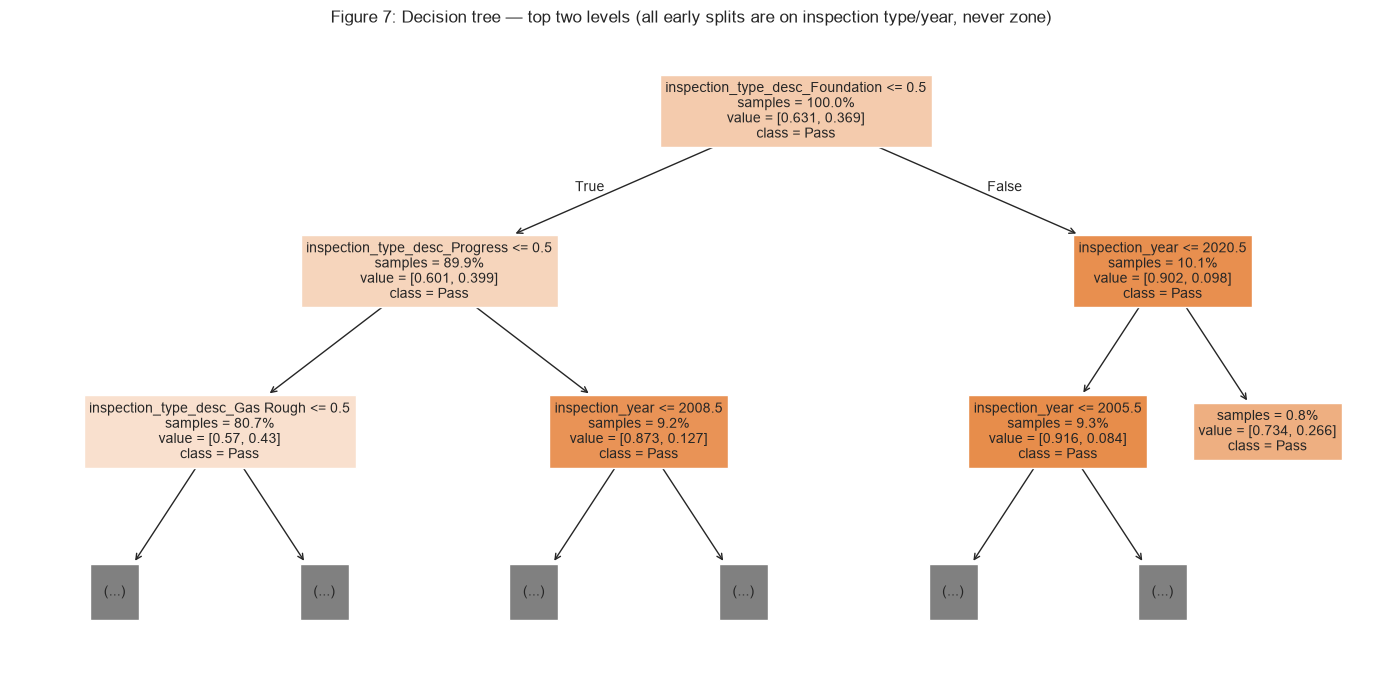

In [19]:
# Figure 7: top of the fitted decision tree
fig, ax = plt.subplots(figsize=(14,7))
plot_tree(dtree, feature_names=list(X.columns), class_names=['Pass','Fail'],
          filled=True, max_depth=2, fontsize=10, impurity=False, proportion=True, ax=ax)
ax.set_title('Figure 7: Decision tree — top two levels (all early splits are on inspection type/year, never zone)')
plt.tight_layout(); plt.savefig('figures/fig7_tree.png', dpi=150); plt.show()

### 7.5 Random Forest
An ensemble of decorrelated trees: reduces single-tree variance and yields a robust feature-importance ranking aggregated across hundreds of diverse trees. Its evidentiary role here is triangulation — if a flexible, non-linear ensemble *also* assigns zone near-zero importance, the "zone is negligible" conclusion cannot be an artifact of logistic regression's linearity.

In [20]:
rforest = RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=50,
                                 random_state=RANDOM_STATE, n_jobs=-1)
rforest.fit(X_train, y_train)
importance = pd.DataFrame({'feature': X.columns, 'importance': rforest.feature_importances_})
importance = importance.sort_values('importance', ascending=False)
zone_imp = importance[importance['feature'].str.startswith('zone_')]['importance'].sum()
print(f"Total importance attributed to zone features: {zone_imp*100:.2f}%")
print(f"Total importance attributed to type + year:  {(1-zone_imp)*100:.2f}%")
importance.head(10)

Total importance attributed to zone features: 1.40%
Total importance attributed to type + year:  98.60%


,feature,importance
6,inspection_type_desc_Foundation,0.2118
0,inspection_year,0.1976
9,inspection_type_desc_Gas Rough,0.1778
11,inspection_type_desc_Progress,0.1639
8,inspection_type_desc_Gas Final,0.0897
4,inspection_type_desc_FP Rough,0.0462
5,inspection_type_desc_Final,0.0395
7,inspection_type_desc_Framing,0.0321
13,inspection_type_desc_Rough,0.0128
10,inspection_type_desc_Occupancy,0.0116


### 7.7 Five-fold cross-validation (stability check)

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, model in [('Logistic Regression', logreg),
                    ('Decision Tree', dtree),
                    ('Random Forest', rforest)]:
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    print(f"{name:25s} ROC-AUC: {scores.mean():.4f} (+/- {scores.std():.4f})")

Logistic Regression       ROC-AUC: 0.6803 (+/- 0.0029)
Decision Tree             ROC-AUC: 0.6694 (+/- 0.0035)
Random Forest             ROC-AUC: 0.7199 (+/- 0.0041)


## Chapter 8 — Model Evaluation
### 8.1 Evaluation on the held-out test set
All three models are scored on the same 30% test set (31,639 records) at the standard 0.5 decision threshold. Because the classes are imbalanced (63:37), accuracy is reported but not emphasized, and the threshold-independent metrics (ROC-AUC and PR-AUC) carry the most weight in the comparison.

In [22]:
def evaluate(name, model):
    proba = model.predict_proba(X_test)[:,1]
    pred = (proba >= 0.5).astype(int)
    pr, rc = precision_recall_curve(y_test, proba)[:2]
    return {'Model': name,
            'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred),
            'Recall': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred),
            'ROC-AUC': roc_auc_score(y_test, proba),
            'PR-AUC': auc(rc, pr)}

results = pd.DataFrame([
    evaluate('Logistic Regression', logreg),
    evaluate('Decision Tree', dtree),
    evaluate('Random Forest', rforest),
]).set_index('Model').round(4)
results

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression,0.6741,0.8067,0.1524,0.2564,0.6768,0.5573
Decision Tree,0.6667,0.8530,0.1159,0.2041,0.6698,0.6354
Random Forest,0.6787,0.7059,0.2198,0.3353,0.7200,0.6054


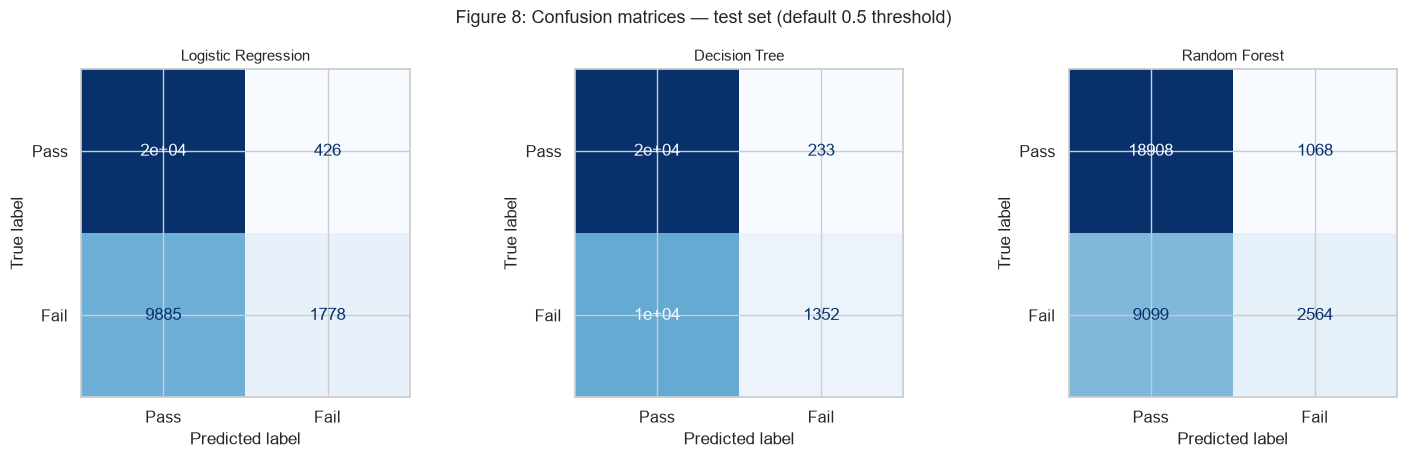

In [23]:
# Figure 8: confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15,4.6))
for ax, (name, model) in zip(axes.flat, [
        ('Logistic Regression', logreg),
        ('Decision Tree', dtree),
        ('Random Forest', rforest)]):
    pred = model.predict(X_test)
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=['Pass','Fail']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=11)
plt.suptitle('Figure 8: Confusion matrices — test set (default 0.5 threshold)', fontsize=13)
plt.tight_layout(); plt.savefig('figures/fig8_confusion.png', dpi=150); plt.show()

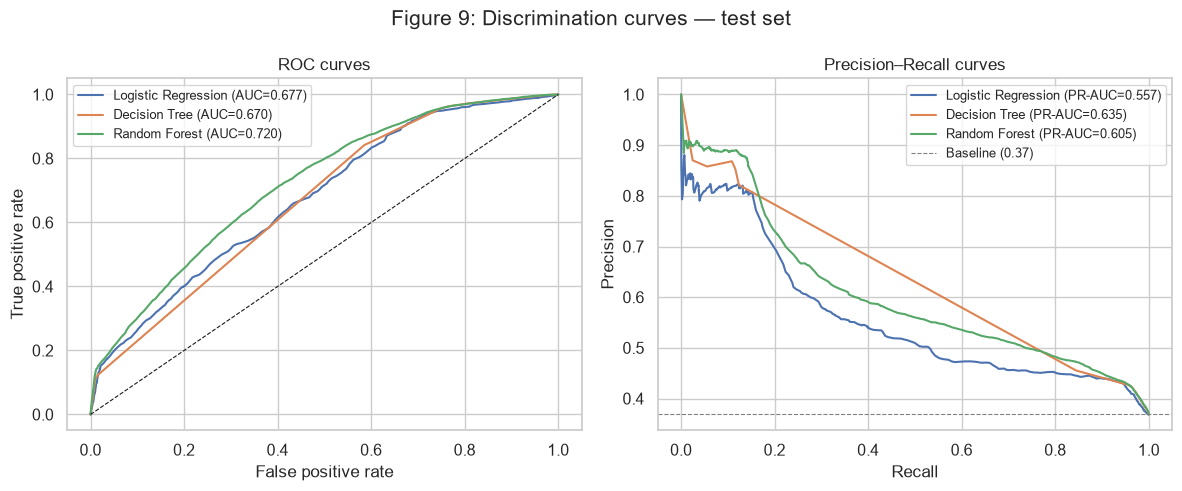

In [24]:
# Figure 9: ROC and Precision-Recall curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))
for name, model in [('Logistic Regression', logreg), ('Decision Tree', dtree),
                    ('Random Forest', rforest)]:
    proba = model.predict_proba(X_test)[:,1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax1.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, proba)
    ax2.plot(rc, pr, label=f"{name} (PR-AUC={auc(rc, pr):.3f})")
ax1.plot([0,1],[0,1],'k--', lw=0.8); ax1.set_xlabel('False positive rate'); ax1.set_ylabel('True positive rate')
ax1.set_title('ROC curves'); ax1.legend(fontsize=9)
ax2.axhline(y_test.mean(), ls='--', color='gray', lw=0.8, label=f'Baseline ({y_test.mean():.2f})')
ax2.set_xlabel('Recall'); ax2.set_ylabel('Precision'); ax2.set_title('Precision–Recall curves'); ax2.legend(fontsize=9)
plt.suptitle('Figure 9: Discrimination curves — test set')
plt.tight_layout(); plt.savefig('figures/fig9_curves.png', dpi=150); plt.show()

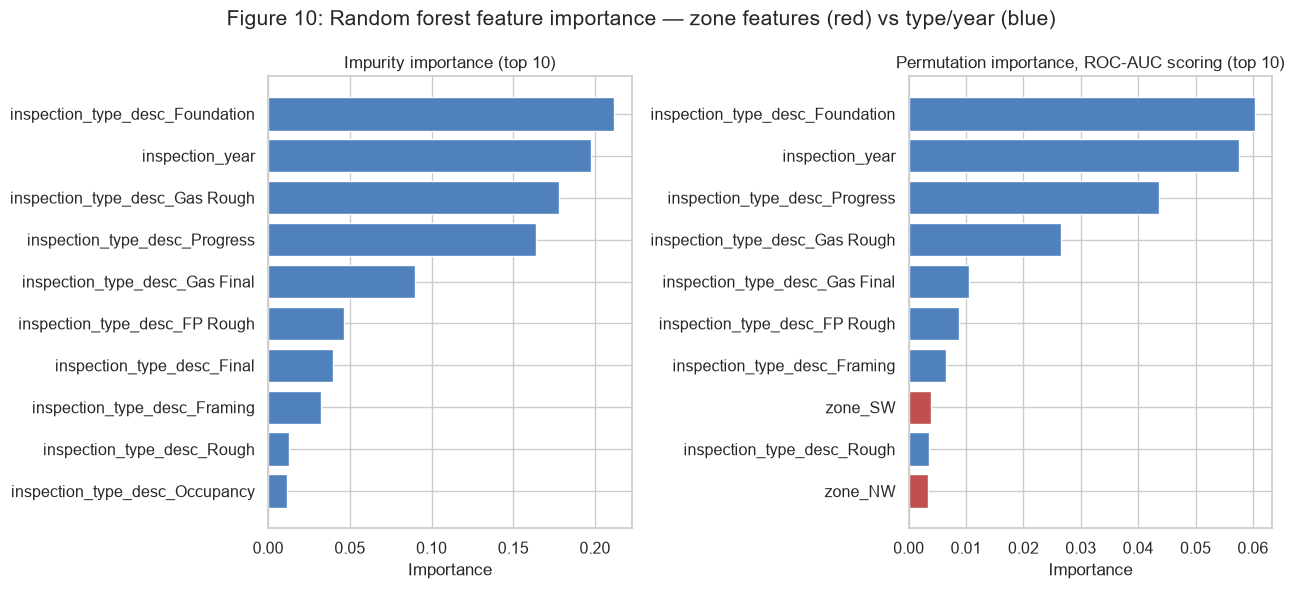

Zone share of permutation importance: 4.49%
Zone share of impurity importance:    1.40%


In [25]:
# Figure 10: Random forest importance — impurity vs permutation (robustness check)
from sklearn.inspection import permutation_importance
perm = permutation_importance(rforest, X_test, y_test, n_repeats=10, scoring='roc_auc',
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_df = pd.DataFrame({'feature': X.columns, 'importance': perm.importances_mean}).sort_values('importance')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13,6))
imp_rf = importance.sort_values('importance').tail(10)
colors_rf = ['#c0504d' if f.startswith('zone_') else '#4f81bd' for f in imp_rf['feature']]
ax1.barh(imp_rf['feature'], imp_rf['importance'], color=colors_rf)
ax1.set_title('Impurity importance (top 10)')
imp_pm = perm_df.tail(10)
colors_pm = ['#c0504d' if f.startswith('zone_') else '#4f81bd' for f in imp_pm['feature']]
ax2.barh(imp_pm['feature'], imp_pm['importance'], color=colors_pm)
ax2.set_title('Permutation importance, ROC-AUC scoring (top 10)')
for ax in (ax1, ax2): ax.set_xlabel('Importance')
plt.suptitle('Figure 10: Random forest feature importance — zone features (red) vs type/year (blue)')
plt.tight_layout(); plt.savefig('figures/fig10_importance.png', dpi=150); plt.show()

zone_perm = perm_df[perm_df['feature'].str.startswith('zone_')]['importance'].clip(lower=0).sum()
total_perm = perm_df['importance'].clip(lower=0).sum()
print(f"Zone share of permutation importance: {zone_perm/max(total_perm,1e-9)*100:.2f}%")
print(f"Zone share of impurity importance:    {zone_imp*100:.2f}%")

## Conclusions
1. **Zone is statistically significant but practically negligible.** Chi-square rejects independence (p < 0.001), yet Cramér's V ≈ 0.015 and the mix-adjusted residual is ~0.1pp. The significance is a large-sample artifact.
2. **The conclusion is triangulated.** Logistic regression odds ratios (all zone effects within 2% of 1.0), decision-tree split structure (no zone splits in the top levels), and random-forest importance (zone ≈ 1.4% of impurity importance and ≈ 4.5% of permutation importance) all agree. Three structurally different methods reach the same answer.
3. **Discrimination has a real ceiling.** The random forest reaches ROC-AUC 0.720 versus 0.67–0.68 for logistic regression and the single tree — evidence of genuine non-linear year × type structure — but no model exceeds 0.72, because zone, type, and year do not contain enough information to separate individual passes from failures more sharply.
4. **Recall is low for all models at the default threshold (0.12–0.22)** — an expected consequence of the 63:37 class imbalance, documented as a limitation. Threshold-independent metrics (ROC-AUC, PR-AUC) are therefore the primary basis of comparison; cost-sensitive weighting or threshold tuning would be the natural extension if a deployment required higher failure detection.
5. **Inspection type and year carry essentially all the signal.** Resources aimed at reducing failures should target high-risk inspection types (gas work) and boom-period workload effects, not geographic zones.